<a href="https://colab.research.google.com/github/swanjala849-Mas/Machine-Learning/blob/main/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install scikit-learn matplotlib

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [3]:
# Load data
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
target_names = iris.target_names

In [5]:
import pandas as pd

# Convert the sklearn Bunch to a pandas DataFrame for easier previewing
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['target_name'] = df['target'].apply(lambda x: iris.target_names[x])

display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [6]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.3, random_state=42
)

In [7]:
# Create and train the decision tree
# Common hyperparameters to control tree growth:
clf = DecisionTreeClassifier(
criterion="gini", # or "entropy"
max_depth=3, # limit depth to reduce overfitting
min_samples_split=2,
min_samples_leaf=1,
random_state=42
)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [8]:
# Make predictions and evaluate
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



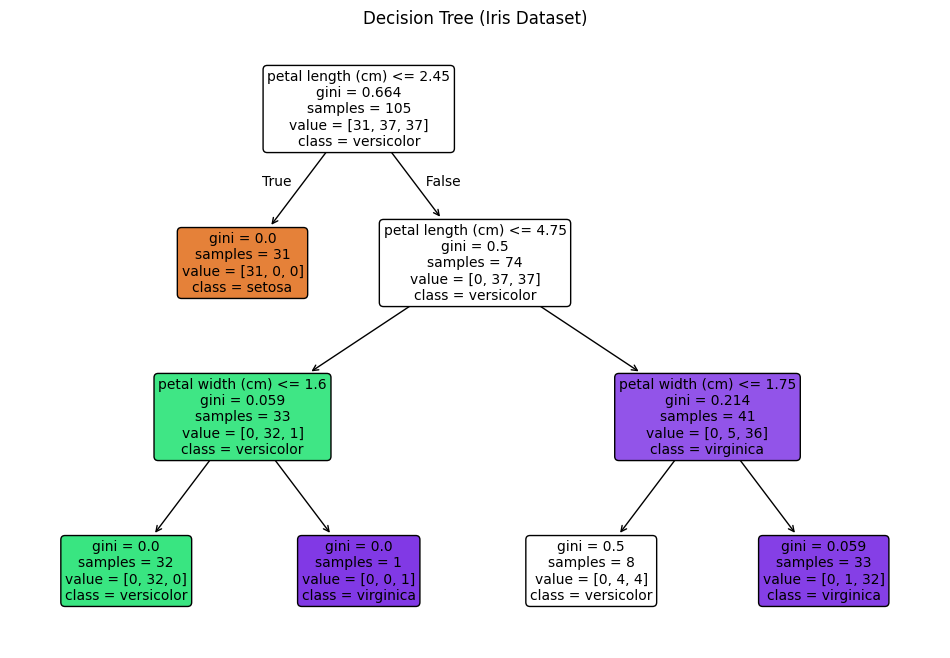

In [9]:
# Visualize the tree
plt.figure(figsize=(12, 8))
plot_tree(
clf,
feature_names=feature_names,
class_names=target_names,
filled=True,
rounded=True,
fontsize=10
)
plt.title("Decision Tree (Iris Dataset)")
plt.show()

In [10]:
# Text representation of the rules
print("\nText rules:")
print(export_text(clf, feature_names=list(feature_names)))


Text rules:
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal length (cm) <= 4.75
|   |   |--- petal width (cm) <= 1.60
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.60
|   |   |   |--- class: 2
|   |--- petal length (cm) >  4.75
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- class: 2



In [11]:
# Example prediction on a new sample
sample = [[5.1, 3.5, 1.4, 0.2]] # sepal length, sepal width, petal length, petal width
prediction = clf.predict(sample)
print(f"\nPredicted class for sample {sample[0]}: {target_names[prediction[0]]}")


Predicted class for sample [5.1, 3.5, 1.4, 0.2]: setosa
